# CsI–SiPM：完整已有母事件池的当前读出选择核查

2026-11-02。按要求先用英文提交并push上一轮分析：**4a00b1c**，`Evaluate CsI charge selection and multiscale fluctuation constraints`；已核对远端main与本地HEAD一致，再开展本轮。

[上一轮电荷与多尺度分析](codex_0001_csi_charge_scale_constraints.ipynb)只使用最初选中的3,661个母事件。原Q范围或质量切选之外的事件无法补回，因此尚不能判断队列截断是否影响带宽结论。本轮对现有完整Geant4 ROOT母事件池重新生成当前响应的ADC，再应用当前质量与电荷选择。

**母事件总数256,000：Co60为64,000，Am241为192,000，各有4个原始输运批次。新增独立输运及实验事件均为0。** 每个母事件保留原雪崩历史，使用当前/零CV响应及r0/r1两条读出流，共1,024,000条逻辑读出。r0沿用原噪声种子，r1是预先指定的正编号全部读出噪声敏感性。默认参数和正式PID不变。


In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/full_selection_20261102'
def read(path):return json.loads(Path(path).read_text())
def fmt(x):return '不可估计' if x is None else f'{x:.4g}'
def ci(x):return '不可估计' if x['CI95'] is None else '['+', '.join(fmt(v) for v in x['CI95'])+f"] ({x['valid_draws']}/512)"
def table(head,rows):return '\n'.join(['|'+'|'.join(head)+'|','|'+'|'.join(['---']*len(head))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
p=read(OUT/'protocol.json');a=read(OUT/'analysis.json');selection=read(OUT/'selection_summary.json');d=read(OUT/'decision.json')
display(Markdown('**本轮完成内容：**'+d['conclusion_zh']))
for text in d['findings_zh']:display(Markdown(text))
print('已推送检查点:',p['checkpoint_commit'],'已有母事件:',p['available_existing_mothers'],'逻辑读出:',p['logical_readout_records'])

已推送检查点: 4a00b1c4c6fabd9e8289b51842d28f6bab9cff71 已有母事件: 256000 逻辑读出: 1024000


**本轮完成内容：**完整已有母事件池的当前软件重选没有消除F202过宽：主读出下Co60与Am241的模拟/实测SD比分别为1.235和1.188，第二读出流也保留差异。原队列外事件进入带来的变化较小；零CV仍不能同时满足短、长尺度宽度。已覆盖256000个原Geant4母事件，原队列特征与配对统计逐项闭合，没有重新拟合或采用新参数。

Co60，读出r0：原支持2175个，当前支持2172个，移入9个、移出12个。F202 SD比由原队列/当前Q的1.233变为完整选择的1.235 [1.171, 1.330]；配对变化范围[-0.002, 0.010]。

Co60，r0完整选择下零CV：F50 SD比0.637，F202 SD比1.001；当前响应分别为0.975、1.235。均ADC相对L2为0.0298。

Co60，读出r1：原支持2175个，当前支持2176个，移入60个、移出59个。F202 SD比由原队列/当前Q的1.244变为完整选择的1.245 [1.186, 1.341]；配对变化范围[-0.004, 0.007]。

Co60，r1完整选择下零CV：F50 SD比0.630，F202 SD比1.010；当前响应分别为0.956、1.245。均ADC相对L2为0.0299。

Am241，读出r0：原支持1406个，当前支持1399个，移入21个、移出28个。F202 SD比由原队列/当前Q的1.185变为完整选择的1.188 [1.110, 1.298]；配对变化范围[-0.004, 0.013]。

Am241，r0完整选择下零CV：F50 SD比0.891，F202 SD比1.162；当前响应分别为0.938、1.188。均ADC相对L2为0.0165。

Am241，读出r1：原支持1406个，当前支持1412个，移入87个、移出81个。F202 SD比由原队列/当前Q的1.223变为完整选择的1.215 [1.135, 1.322]；配对变化范围[-0.017, 0.002]。

Am241，r1完整选择下零CV：F50 SD比0.898，F202 SD比1.180；当前响应分别为0.967、1.215。均ADC相对L2为0.0142。

## 1. 完整分母与选择规则

新原生入口`simulation/replay_full_pool.cc`逐母事件读取现有Geant4的完整`Events`树，包含零能量沉积及原质量/电荷失败事件。调用已有`include/`、`src/`中的原生读出类，不改变光学输运、SiPM雪崩、源几何或晶体。只输出无损uint16 ADC用于完整重选，原ADC也复制保存用于逐事件质量闭合；不用旧Q或真值预筛选。

当前参数固定为晚段last20、块128的扩展谱响应；延续原来的完整母事件Bernoulli折分配，每个母事件使用指定折参数。选择规则沿用原实现：14位ADC轨限/幅度/完整积分门标志通过，前触发质量通过，峰值≥200 ADC、t10≥384样点、电荷落在原共同范围内。前触发质量的噪声参考由**每批完整母事件**的基线RMS中位数确定；另记录按折分别取中位数是否改变判定。

Co比较原6个Q箱，Am比较前3个Q箱。原Q范围最高边界包含；内部箱边界延续原规则。源支持边界按既有分箱定义，所有支持箱和正目标半箱都必须有事件。仍采用原实测主带参考，不引入实验粒子真值。

|条件|事件选择|Q分箱|
|---|---|---|
|old_cohort_original_Q|原共同范围队列，不重新切当前质量|原Q|
|old_cohort_current_Q|原队列中当前Q在支持内|当前Q|
|old_cohort_current_selection|原队列，同时当前质量及Q通过|当前Q|
|full_pool_current_selection|完整母事件池，当前质量及Q通过|当前Q|

后两步分别检查当前质量切选以及原队列外的进入事件。不会把进入事件伪装成新增独立Geant4样本。


|源|响应/读出|全部母事件|原支持|当前支持|移入|移出|原共同队列外进入|折参考判定差异|
|---|---|---|---|---|---|---|---|---|
|Co60|current_r0|64000|2175|2172|9|12|9|0|
|Co60|zero_cv_r0|64000|2175|2170|8|13|8|0|
|Co60|current_r1|64000|2175|2176|60|59|60|0|
|Co60|zero_cv_r1|64000|2175|2173|58|60|58|0|
|Am241|current_r0|192000|1406|1399|21|28|11|0|
|Am241|zero_cv_r0|192000|1406|1399|21|28|11|0|
|Am241|current_r1|192000|1406|1412|87|81|54|0|
|Am241|zero_cv_r1|192000|1406|1412|88|82|55|0|

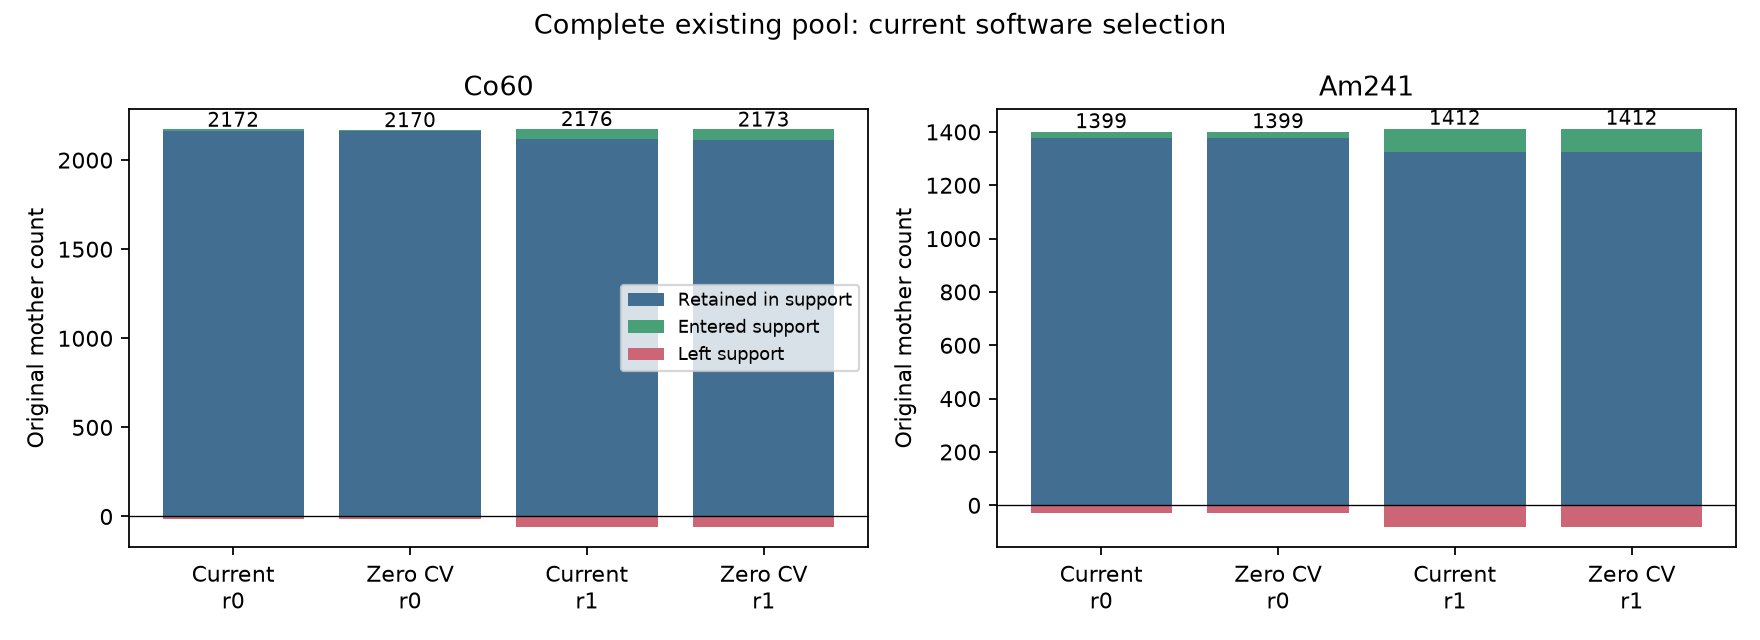

|源|响应/读出|原QC/幅度/时间失败|原低Q|原高Q|alpha家族|gamma家族|衰变电子家族|混合/其他|无沉积|
|---|---|---|---|---|---|---|---|---|---|
|Co60|current_r0|0|7|2|0|9|0|0|0|
|Co60|zero_cv_r0|0|5|3|0|8|0|0|0|
|Co60|current_r1|0|21|39|0|60|0|0|0|
|Co60|zero_cv_r1|0|21|37|0|58|0|0|0|
|Am241|current_r0|0|11|10|21|0|0|0|0|
|Am241|zero_cv_r0|0|11|10|21|0|0|0|0|
|Am241|current_r1|0|54|33|87|0|0|0|0|
|Am241|zero_cv_r1|0|55|33|88|0|0|0|0|

In [2]:
rows=[]
for source,variants in selection.items():
    for v,r in variants.items():rows.append([source,v,r['mothers'],r['old_supported'],r['current_supported'],r['enter_support'],r['leave_support'],r['new_beyond_old_common'],r['fold_reference_QC_disagreement']])
display(Markdown(table(['源','响应/读出','全部母事件','原支持','当前支持','移入','移出','原共同队列外进入','折参考判定差异'],rows)))
display(Image(filename=str(OUT/'figures/full_pool_selection.png')))
rows=[]
truth_names=['alpha家族','gamma家族','衰变电子家族','混合/其他','无沉积']
for source,variants in selection.items():
    for v,r in variants.items():rows.append([source,v,*[r['entrance_reasons'][k] for k in ['old_quality_or_amplitude_or_time_failure','old_below_supported_Q','old_above_supported_Q']],*r['enter_truth']])
display(Markdown(table(['源','响应/读出','原QC/幅度/时间失败','原低Q','原高Q',*truth_names],rows)))

## 2. 保留原抽样，并给新进入母事件补充配对计数

实验继续使用原512组连续采集块计数；原已选母事件的计数逐项不变。设某批完整母事件数为$N$，原共同队列有$K$个母事件，某次抽样在这些母事件上的计数和为$C$。剩余$N-C$次抽样在原未选中的$N-K$个母事件上条件均匀；新需要的每个母事件的类别概率为$1/(N-K)$，其余母事件合为一个剩余类别。

这给出完整母事件多项分布抽样的**精确条件扩展**，不是把新进入的事件当成与旧事件独立的额外样本。每个母事件在两条读出流和两个模型中共用同一个计数。原队列对比的512组结果因此逐项闭合。

每个Q箱继续固定半箱目标质量，并计算加权箱内协方差、均值及中心50%/95%分位宽度，跨支持箱等权汇总。三尺度的规范化和共同/短长差/弯曲轴都沿用上一轮固定参考。所有区间固定响应、参考、已生成噪声和质量阈值，不含重新拟合或装置系统误差。r0与r1分别报告，不能把两条读出当作两倍独立母事件，也不能声称已得到噪声平均的收敛估计。


|源|选择|响应/读出|F50 SD比|F102 SD比|F202 SD比|F202条件95%范围|
|---|---|---|---|---|---|---|
|Co60|old_cohort_original_Q|current_r0|0.9765|1.157|1.232|[1.168, 1.326] (512/512)|
|Co60|old_cohort_original_Q|zero_cv_r0|0.6364|0.8201|0.9965|[0.9467, 1.069] (512/512)|
|Co60|old_cohort_original_Q|current_r1|0.957|1.194|1.251|[1.192, 1.351] (512/512)|
|Co60|old_cohort_original_Q|zero_cv_r1|0.6268|0.8349|1.006|[0.9555, 1.081] (512/512)|
|Co60|old_cohort_current_Q|current_r0|0.9754|1.157|1.233|[1.168, 1.327] (512/512)|
|Co60|old_cohort_current_Q|zero_cv_r0|0.6374|0.8198|0.9972|[0.9465, 1.069] (512/512)|
|Co60|old_cohort_current_Q|current_r1|0.953|1.185|1.244|[1.186, 1.341] (512/512)|
|Co60|old_cohort_current_Q|zero_cv_r1|0.6283|0.8354|1.009|[0.9604, 1.083] (512/512)|
|Co60|old_cohort_current_selection|current_r0|0.9754|1.157|1.233|[1.168, 1.327] (512/512)|
|Co60|old_cohort_current_selection|zero_cv_r0|0.6374|0.8198|0.9972|[0.9465, 1.069] (512/512)|
|Co60|old_cohort_current_selection|current_r1|0.953|1.185|1.244|[1.186, 1.341] (512/512)|
|Co60|old_cohort_current_selection|zero_cv_r1|0.6283|0.8354|1.009|[0.9604, 1.083] (512/512)|
|Co60|full_pool_current_selection|current_r0|0.9748|1.158|1.235|[1.171, 1.33] (512/512)|
|Co60|full_pool_current_selection|zero_cv_r0|0.637|0.8222|1.001|[0.9499, 1.072] (512/512)|
|Co60|full_pool_current_selection|current_r1|0.9563|1.187|1.245|[1.186, 1.341] (512/512)|
|Co60|full_pool_current_selection|zero_cv_r1|0.6301|0.8358|1.01|[0.9592, 1.084] (512/512)|
|Am241|old_cohort_original_Q|current_r0|0.9412|1.049|1.201|[1.122, 1.312] (512/512)|
|Am241|old_cohort_original_Q|zero_cv_r0|0.8921|1.011|1.176|[1.098, 1.281] (512/512)|
|Am241|old_cohort_original_Q|current_r1|0.972|1.134|1.243|[1.155, 1.353] (512/512)|
|Am241|old_cohort_original_Q|zero_cv_r1|0.8956|1.068|1.203|[1.119, 1.316] (512/512)|
|Am241|old_cohort_current_Q|current_r0|0.9381|1.051|1.185|[1.107, 1.296] (512/512)|
|Am241|old_cohort_current_Q|zero_cv_r0|0.8903|1.015|1.159|[1.082, 1.27] (512/512)|
|Am241|old_cohort_current_Q|current_r1|0.969|1.128|1.223|[1.145, 1.327] (512/512)|
|Am241|old_cohort_current_Q|zero_cv_r1|0.8994|1.068|1.185|[1.11, 1.293] (512/512)|
|Am241|old_cohort_current_selection|current_r0|0.9381|1.051|1.185|[1.107, 1.296] (512/512)|
|Am241|old_cohort_current_selection|zero_cv_r0|0.8903|1.015|1.159|[1.082, 1.27] (512/512)|
|Am241|old_cohort_current_selection|current_r1|0.969|1.128|1.223|[1.145, 1.327] (512/512)|
|Am241|old_cohort_current_selection|zero_cv_r1|0.8994|1.068|1.185|[1.11, 1.293] (512/512)|
|Am241|full_pool_current_selection|current_r0|0.9384|1.05|1.188|[1.11, 1.298] (512/512)|
|Am241|full_pool_current_selection|zero_cv_r0|0.8914|1.015|1.162|[1.086, 1.27] (512/512)|
|Am241|full_pool_current_selection|current_r1|0.967|1.127|1.215|[1.135, 1.322] (512/512)|
|Am241|full_pool_current_selection|zero_cv_r1|0.8978|1.067|1.18|[1.104, 1.292] (512/512)|

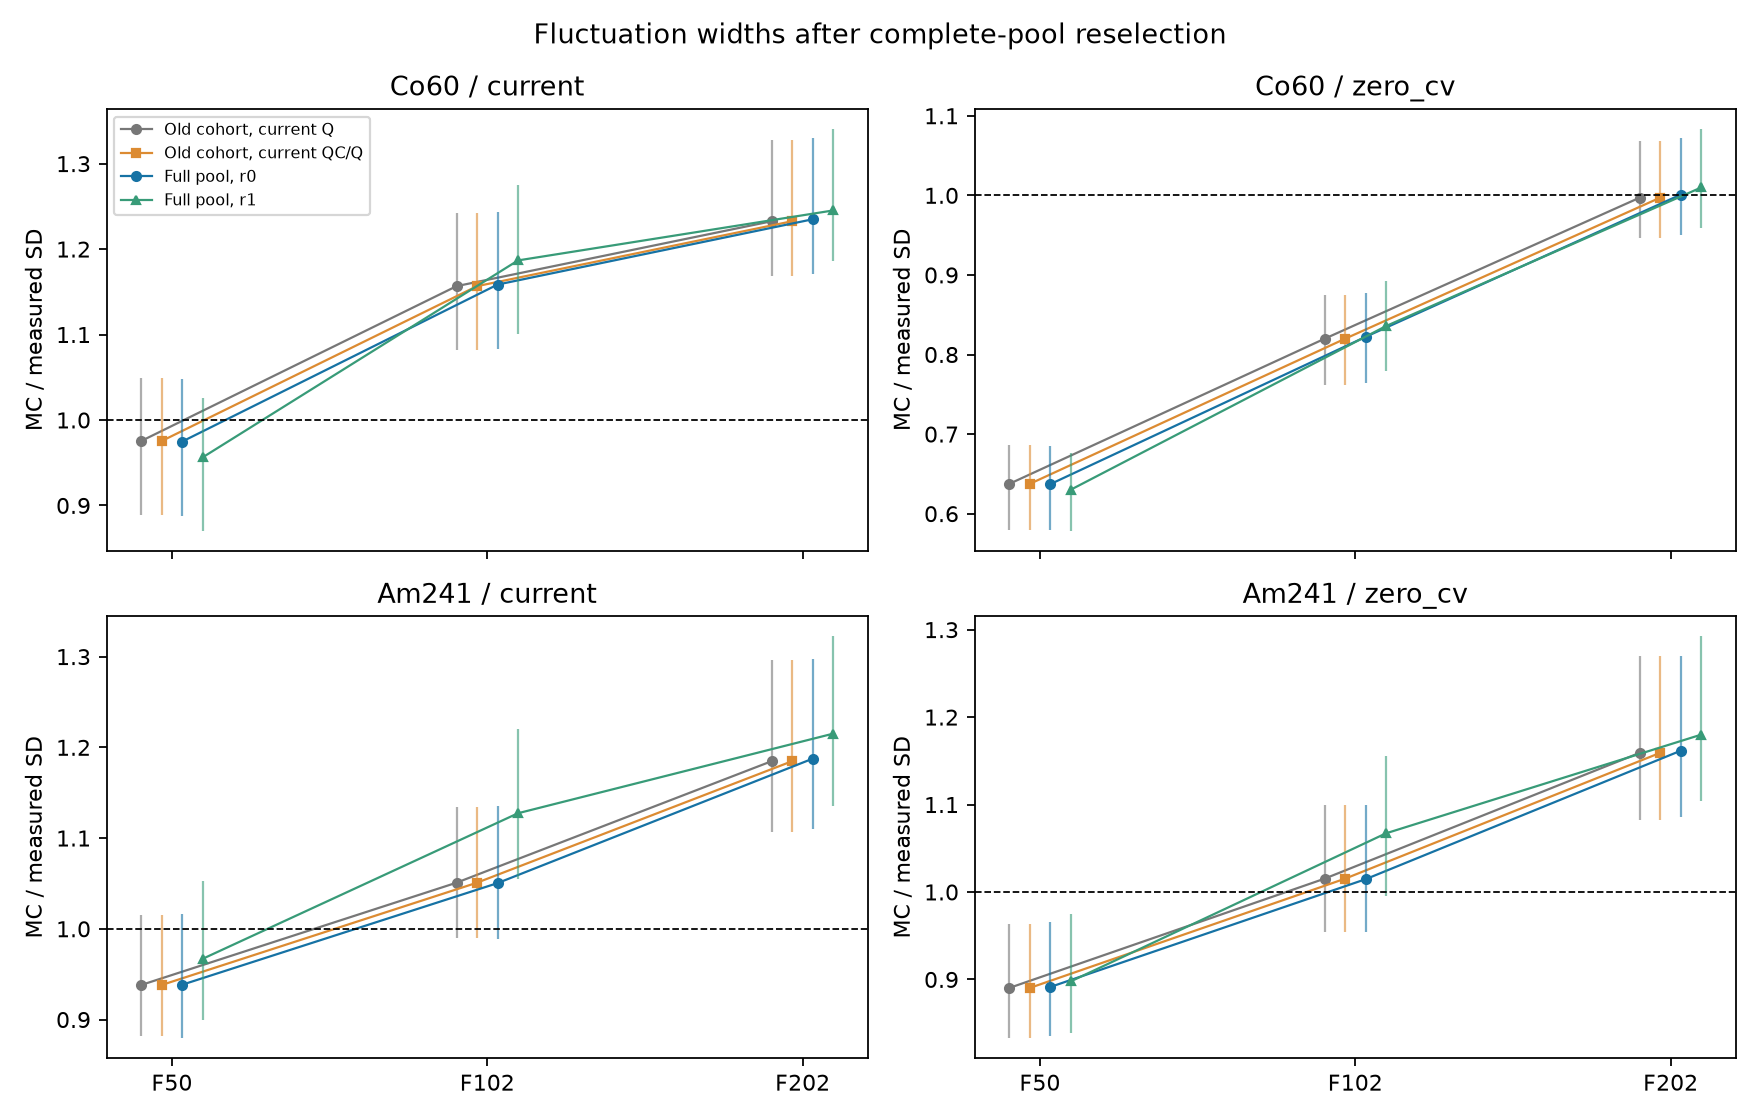

|源|响应/读出|相对条件|F202 SD比变化|配对95%范围|
|---|---|---|---|---|
|Co60|current_r0|old_cohort_current_Q|0.002284|[-0.001706, 0.009733] (512/512)|
|Co60|current_r0|old_cohort_current_selection|0.002284|[-0.001706, 0.009733] (512/512)|
|Co60|zero_cv_r0|old_cohort_current_Q|0.00378|[-0.0004409, 0.01169] (512/512)|
|Co60|zero_cv_r0|old_cohort_current_selection|0.00378|[-0.0004409, 0.01169] (512/512)|
|Co60|current_r1|old_cohort_current_Q|0.001364|[-0.003516, 0.006979] (512/512)|
|Co60|current_r1|old_cohort_current_selection|0.001364|[-0.003516, 0.006979] (512/512)|
|Co60|zero_cv_r1|old_cohort_current_Q|0.0006732|[-0.003574, 0.005304] (512/512)|
|Co60|zero_cv_r1|old_cohort_current_selection|0.0006732|[-0.003574, 0.005304] (512/512)|
|Am241|current_r0|old_cohort_current_Q|0.002755|[-0.004477, 0.0134] (512/512)|
|Am241|current_r0|old_cohort_current_selection|0.002755|[-0.004477, 0.0134] (512/512)|
|Am241|zero_cv_r0|old_cohort_current_Q|0.002411|[-0.0042, 0.01233] (512/512)|
|Am241|zero_cv_r0|old_cohort_current_selection|0.002411|[-0.0042, 0.01233] (512/512)|
|Am241|current_r1|old_cohort_current_Q|-0.007868|[-0.01686, 0.001763] (512/512)|
|Am241|current_r1|old_cohort_current_selection|-0.007868|[-0.01686, 0.001763] (512/512)|
|Am241|zero_cv_r1|old_cohort_current_Q|-0.004774|[-0.01323, 0.005011] (512/512)|
|Am241|zero_cv_r1|old_cohort_current_selection|-0.004774|[-0.01323, 0.005011] (512/512)|

In [3]:
rows=[]
for source,g in a.items():
    for condition,item in g['conditions'].items():
        for v,r in item['variants'].items():rows.append([source,condition,v,*[fmt(r['point'][f'F{s}_SD_ratio']) for s in [50,102,202]],ci(r['CI95']['F202_SD_ratio'])])
display(Markdown(table(['源','选择','响应/读出','F50 SD比','F102 SD比','F202 SD比','F202条件95%范围'],rows)))
display(Image(filename=str(OUT/'figures/full_pool_scales.png')))
rows=[]
for source,g in a.items():
    for v,r in g['conditions']['full_pool_current_selection']['variants'].items():
        for ref in ['old_cohort_current_Q','old_cohort_current_selection']:
            c=r['changes'][ref];rows.append([source,v,ref,fmt(c['point']['F202_SD_ratio']),ci(c['CI95']['F202_SD_ratio'])])
display(Markdown(table(['源','响应/读出','相对条件','F202 SD比变化','配对95%范围'],rows)))

## 3. 同时检查PID、三尺度协方差与平均波形

仅F202宽度接近1不能证明模型成功。仍需共同检查F50/F102、QDC/平均时间/PCA的标准差、中心50%及95%宽度、PID与F的完整协方差。下图协方差差值按对应实测标准差乘积归一化；F的三个时间尺度来自重叠滤波，不是独立物理频带。

平均波形使用基线扣除后的绝对ADC，不逐事件归一化幅度。积分门以整数对齐样点为起点；曲线变化可以由事件进入/退出和权重变化引起，本轮没有为此重新拟合平均响应。


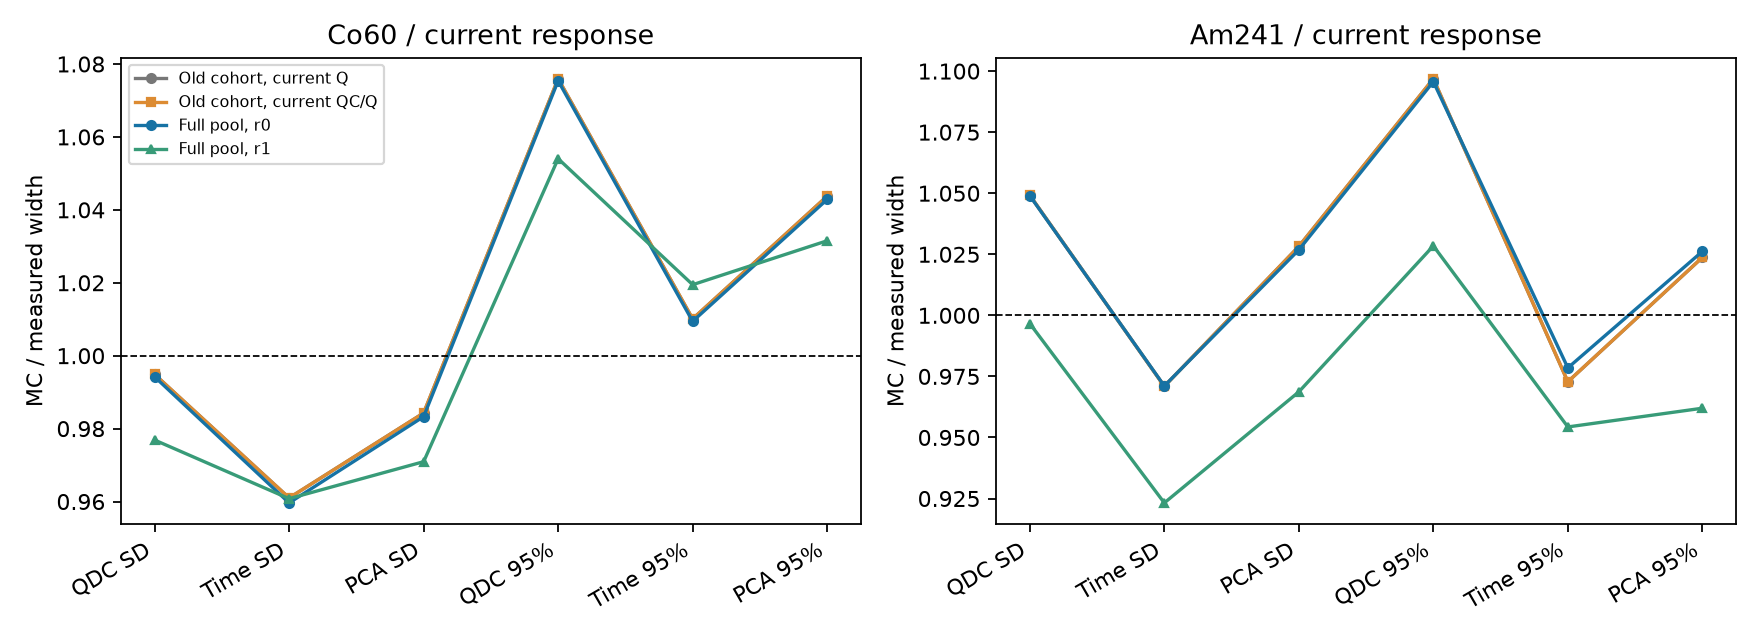

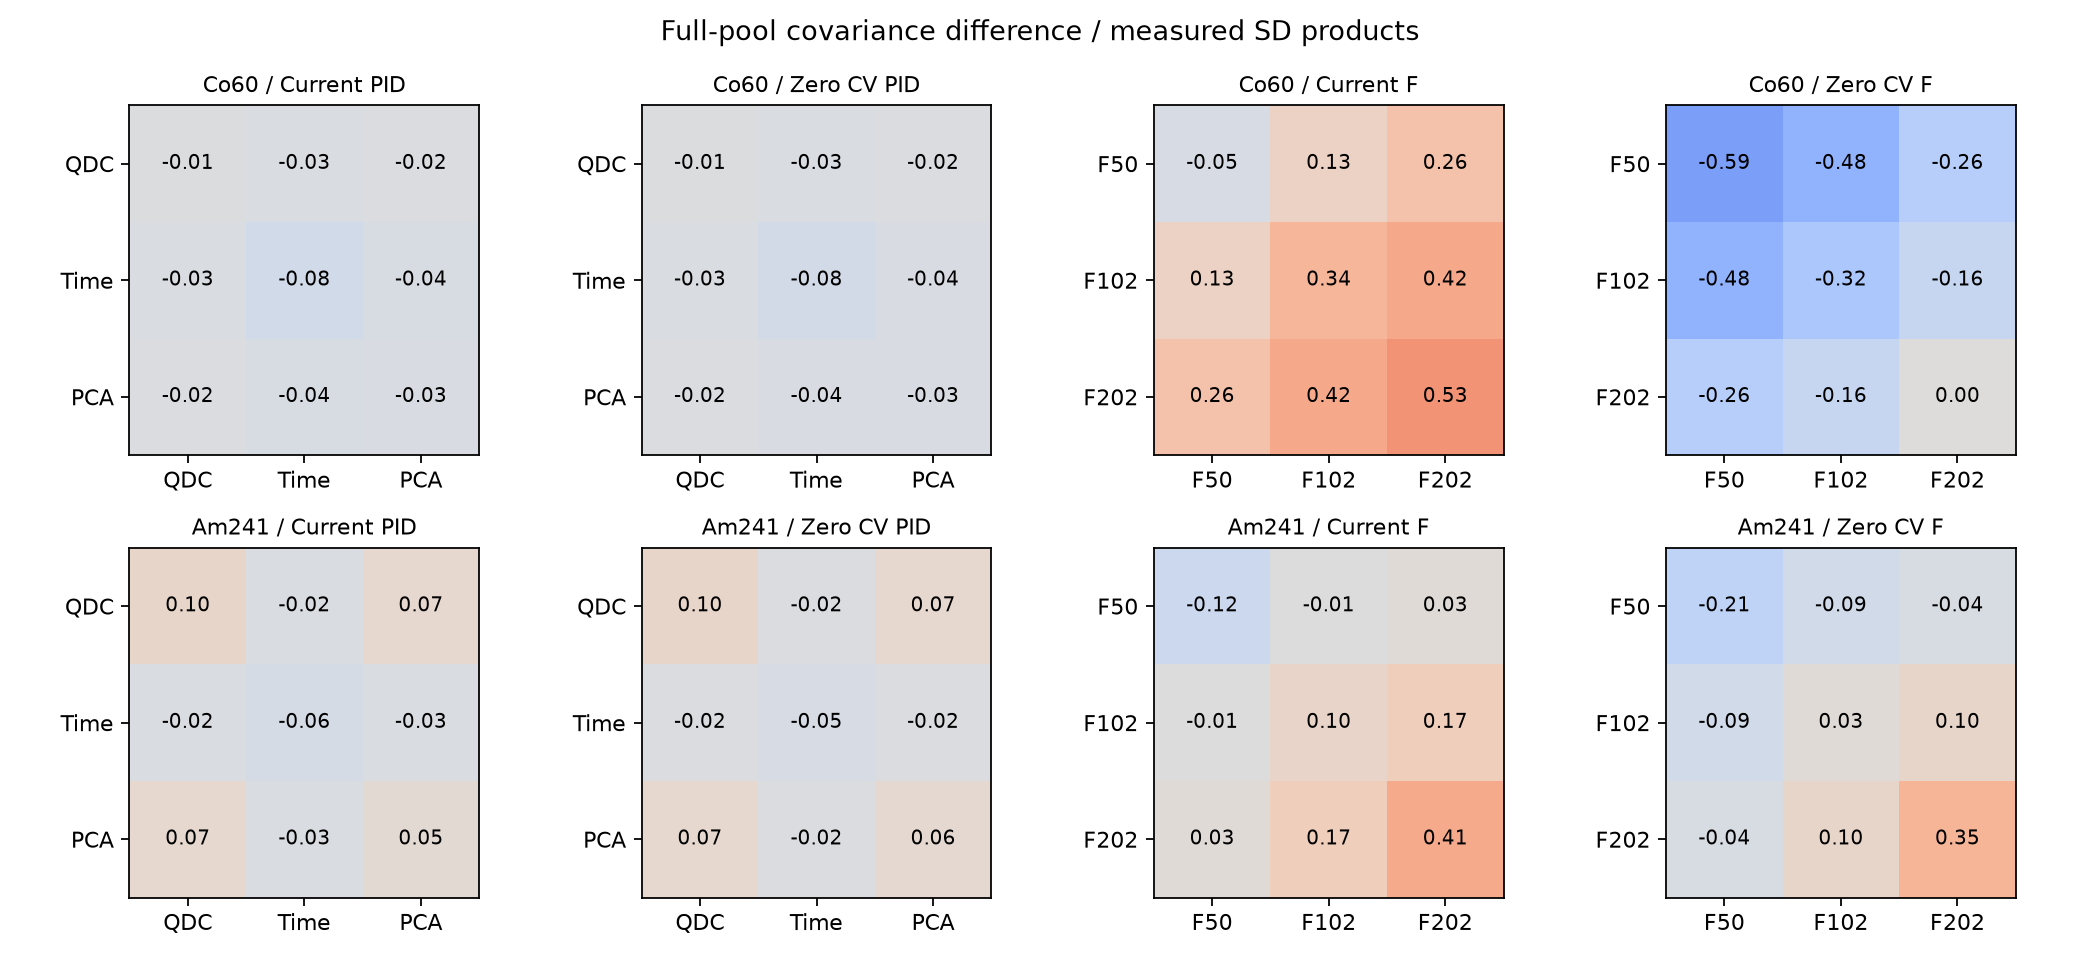

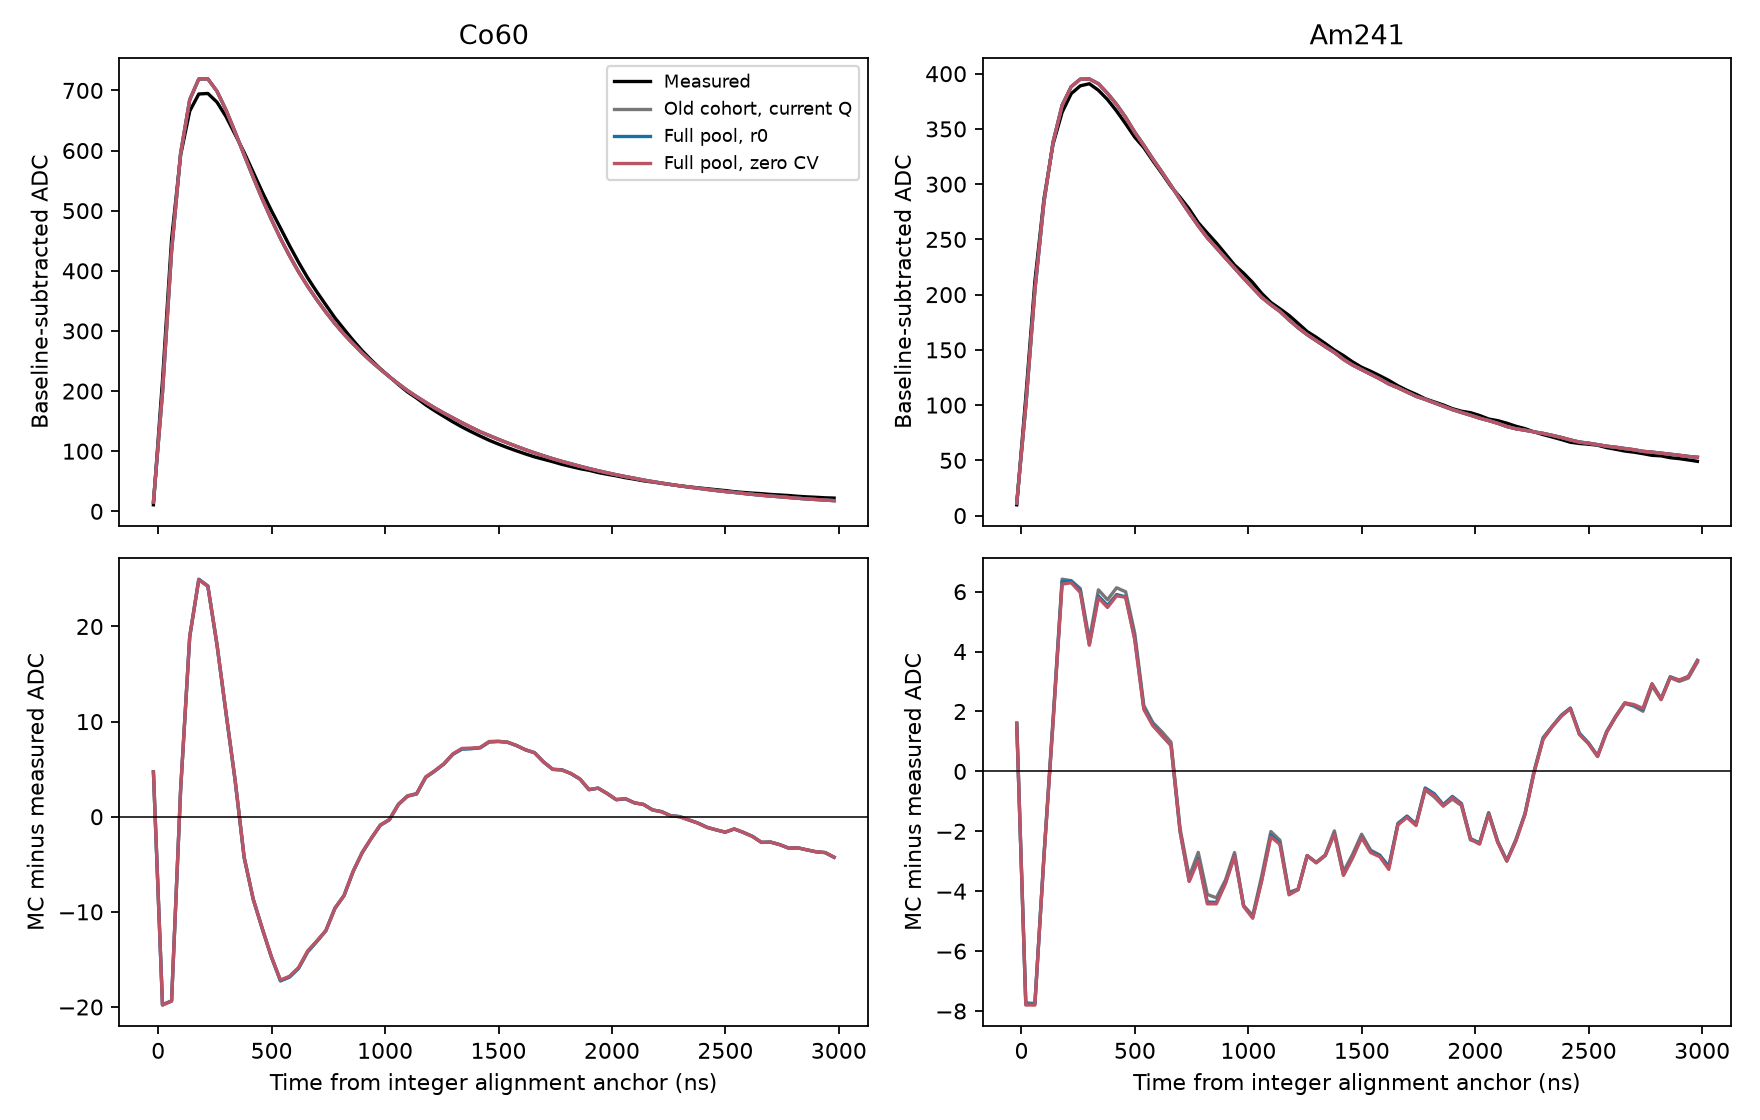

|源|响应/读出|均ADC相对L2|PID协方差误差|F协方差误差|QDC 95%宽比|平均时间95%宽比|PCA 95%宽比|
|---|---|---|---|---|---|---|---|
|Co60|current_r0|0.02984|0.03781|0.3192|1.075|1.009|1.043|
|Co60|zero_cv_r0|0.02983|0.03626|0.3501|1.079|1.017|1.045|
|Co60|current_r1|0.02995|0.053|0.3537|1.054|1.019|1.032|
|Co60|zero_cv_r1|0.02993|0.05539|0.3426|1.049|1.025|1.032|
|Am241|current_r0|0.01654|0.05687|0.1677|1.096|0.9785|1.026|
|Am241|zero_cv_r0|0.01654|0.05691|0.1512|1.098|0.9771|1.023|
|Am241|current_r1|0.01424|0.09725|0.2305|1.028|0.9543|0.962|
|Am241|zero_cv_r1|0.01423|0.0997|0.1757|1.029|0.9557|0.9603|

In [4]:
display(Image(filename=str(OUT/'figures/full_pool_pid.png')))
display(Image(filename=str(OUT/'figures/full_pool_covariance.png')))
display(Image(filename=str(OUT/'figures/full_pool_mean_adc.png')))
rows=[]
for source,g in a.items():
    for v,r in g['conditions']['full_pool_current_selection']['variants'].items():rows.append([source,v,*[fmt(r['point'][n]) for n in ['mean_ADC_relative_L2','PID_covariance_relative_error','F_covariance_relative_error','QDC_width95_ratio','negative_mean_time_us_width95_ratio','PCA_width95_ratio']]])
display(Markdown(table(['源','响应/读出','均ADC相对L2','PID协方差误差','F协方差误差','QDC 95%宽比','平均时间95%宽比','PCA 95%宽比'],rows)))

## 4. 核验范围、局限与下一步

原256000条ADC的积分电荷、质量选择、能量标签与旧抽取记录核对；原3,661个选中母事件在四种读出上的特征均逐条闭合。原队列/原Q和原队列/当前Q的512组抽样指标继续闭合上一轮记录。另用旧原生重放ROOT做ADC逐样点核对。结果与代码哈希、源文件快照及实际执行的笔记一并封存。

`protocol.json`在任何新重放前冻结；预执行时修正准备脚本的输入文件名并明确处理未选中NaN波形，保留`pre_execution_protocol_v1.json`，未变更物理参数、选择规则、种子或计划对比。`analysis_protocol.json`在新统计前冻结分析源码及输入。构建曾在CMake生成完成前提前触发，等待生成完成后正常构建；没有产生科学结果的失败构建或参数挑选。

复现入口：`prepare_full_selection.py` → 新构建目录中的`replay_full_pool`及`run_full_selection.py` → `extract_full_selection.py` → `analyze_full_selection.py` → `report_full_selection.py` → 本笔记生成器 → `verify_full_selection.py`及`--archive`。完整重跑应使用新的结果目录；输出拒绝静默覆盖。共享文献库未修改。


In [5]:
display(read(OUT/'algebra_tests.json'))
for source,g in a.items():print(source,'完全相同的原队列特征条数:',g['inherited_feature_records_identical'],'逐项闭合抽样数:',g['inherited_bootstrap_draws_identical'])
for x in d['limitations_zh']:display(Markdown('边界：'+x))
display(Markdown('**下一步：**'+d['next_work_zh']))

Co60 完全相同的原队列特征条数: {'current_r0': 2175, 'zero_cv_r0': 2175, 'current_r1': 2175, 'zero_cv_r1': 2175} 逐项闭合抽样数: 512
Am241 完全相同的原队列特征条数: {'current_r0': 1486, 'zero_cv_r0': 1486, 'current_r1': 1486, 'zero_cv_r1': 1486} 逐项闭合抽样数: 512


{'comparisons': {'Co60': {'QC_events': 600,
   'original_and_current_charge_statistics_identical': True},
  'Am241': {'QC_events': 600,
   'original_and_current_charge_statistics_identical': True}},
 'conditional_multinomial_draws': 20000,
 'excluded_invalid_waveform_not_used': True,
 'code_sha256': '8a0f5b3144c027dedda1a5ffdce6ab7e423f95bb4cab55ad99385ac407e5a192'}

边界：这是已有256000个母事件的完整重选，不是新增独立输运，也不是未经探索的验证集。

边界：仅覆盖last20/B128及两个预定读出流。r0保留原噪声，r1是一条正编号噪声敏感性；没有声称两个流已收敛到噪声平均。

边界：512次区间固定已生成读出、全局QC阈值、PCA、响应和Q目标，不含重拟合、读出重抽样或装置系统误差。

边界：统计仍以共同电荷支持和实测主带为条件。模拟选择率是给定源几何下的软件切选，不是实测硬件触发效率；MC祖先标签不是实测事件真值。

边界：Am241含alpha及gamma/电子成分。尚未由这些结果唯一辨识PID带宽的微观成因，也未证明所有PID维度及尾部一致。

**下一步：**后续候选模型应在完整母事件池上应用当前质量与电荷选择，再共同约束F50/F102/F202协方差、平均ADC、PID核心与尾宽。先试能区分短长尺度相关波动的最小残差结构；通过联合检查后再冻结参数并做独立Geant4输运验证。